# getting specific spectra from NOMAD

In [3]:
import requests
import getpass
import json
import pandas as pd
from typing import Dict, List, Tuple
from collections import Counter
import os
import matplotlib.pyplot as plt

### Access NOMAD

In [ ]:
# --- Function to get an access token from the NOMAD API ---
def get_access_token(
    username: str, password: str, url: str, timeout_in_sec: int = 10
) -> str:
    """Authenticates with the NOMAD API and returns an access token."""
    response = requests.post(
        f"{url}/auth/token",
        data={"username": username, "password": password},
        timeout=timeout_in_sec,
    )
    response.raise_for_status()  # This will raise an error if login fails
    return response.json()["access_token"]

# --- Configuration ---
URL = "https://nomad.nanolab.dtu.dk/nomad-oasis/api/v1"

# --- Connect and Prepare Headers for Future Use ---
access_token = getpass.getpass("Enter your NOMAD personal access token: ").strip()
if not access_token:
    raise ValueError("A NOMAD personal access token is required.")
headers = {"Authorization": f"Bearer {access_token}"}
print("Authorization header configured; the API connection will be checked on the first request.")

✅ Connection successful. Access token obtained.
The 'headers' variable is now ready for future API calls.


### Just Run this cell
define ploting functions

In [ ]:
# ============================================================================
# PLOTTING FUNCTION - Creates XRD spectrum plots
# ============================================================================

def plot_xrd_spectrum(xrd_data: dict, entry_id: str):
    """
    Plot XRD spectrum and save as PNG.
    
    Parameters:
    -----------
    xrd_data : dict
        Dictionary containing 'two_theta', 'intensity', 'entry_name', 'entry_id'
    entry_id : str
        Entry ID for filename
    """
    two_theta = xrd_data['two_theta']
    intensity = xrd_data['intensity']
    entry_name = xrd_data.get('entry_name', 'XRD Spectrum')
    
    # Create plot
    plt.figure(figsize=(10, 6))
    plt.plot(two_theta, intensity, 'b-', linewidth=1)
    plt.xlabel('2θ (degrees)', fontsize=12)
    plt.ylabel('Intensity (a.u.)', fontsize=12)
    plt.title(f'XRD Spectrum\n{entry_name}', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    
    # Save plot
    filename = f'xrd_spectrum_{entry_id}.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()
    
    return filename

### Choose your upload and a relative position

In [ ]:
# ============================================================================
# STEP 1: USER INPUT - Specify upload and position
# 📝 EDIT THESE VALUES:
UPLOAD_NAME = "anait_0021_Ba_BL"  # Example: "anait_0021_Ba_BL" or "anait_0010_RTP"
POSITION = "BL"  # Example: "FL", "FR", "BL", "BR", "C", etc. (or leave empty "" for all)
SAMPLE_TYPE = ""  # Optional: "sputtering", "RTP", or "" for both
# ============================================================================

print("="*80)
print("🔍 SEARCHING FOR XRD MEASUREMENTS")
print("="*80)
print(f"\n📋 Search parameters:")
print(f"   Upload name: {UPLOAD_NAME}")
print(f"   Position: {POSITION if POSITION else 'All positions'}")
print(f"   Sample type: {SAMPLE_TYPE.upper() if SAMPLE_TYPE else 'All types (Sputtering & RTP)'}")
print("\n⏳ Searching...")

# Search for XRD entries
xrd_query = {
    "owner": "visible",
    "query": {
        "and": [
            {"entry_type:all": ["DTUXRDMeasurement"]},
            {"authors.name": "Anat Itzhak"}
        ]
    },
    "pagination": {"page_size": 100},
    "required": {"include": ["entry_id", "entry_name", "mainfile", "upload_id"]}
}

response = requests.post(
    f"{URL}/entries/query",
    headers=headers,
    json=xrd_query,
    timeout=60
)

if response.status_code == 200:
    data = response.json()
    all_xrd_entries = data.get('data', [])
    
    # Filter by upload name and position
    matching_entries = []
    
    for entry in all_xrd_entries:
        entry_name = entry.get('entry_name', '')
        mainfile = entry.get('mainfile', '')
        
        # Check if upload name matches
        if UPLOAD_NAME.lower() in entry_name.lower() or UPLOAD_NAME.lower() in mainfile.lower():
            # Check position if specified
            if POSITION:
                if POSITION.upper() in entry_name.upper() or POSITION.upper() in mainfile.upper():
                    matching_entries.append(entry)
            else:
                matching_entries.append(entry)
    
    print("\n" + "="*80)
    print(f"📊 FOUND {len(matching_entries)} XRD ENTRY(IES)")
    print("="*80)
    
    if matching_entries:
        # Now fetch full data to see how many measurement points each has
        print(f"\n⏳ Fetching detailed information...\n")
        
        available_xrd_points = {}
        point_counter = 0
        
        for entry_idx, entry in enumerate(matching_entries, 1):
            entry_id = entry.get('entry_id')
            entry_name = entry.get('entry_name', 'Unknown')
            
            # Fetch full archive to see measurement points
            xrd_archive_query = {
                "owner": "visible",
                "query": {"entry_id": entry_id},
                "pagination": {"page_size": 1},
                "required": {"data": "*"}
            }
            
            response = requests.post(
                f"{URL}/entries/archive/query",
                headers=headers,
                json=xrd_archive_query,
                timeout=120
            )
            
            if response.status_code == 200:
                archive_data = response.json()
                entries_data = archive_data.get('data', [])
                
                if entries_data:
                    archive = entries_data[0].get('archive', {})
                    data_section = archive.get('data', {})
                    
                    # Check 'results' section for measurement points
                    results = data_section.get('results', [])
                    
                    if isinstance(results, list) and len(results) > 0:
                        num_points = len(results)
                        
                        print(f"📁 Entry [{entry_idx}]: {entry_name}")
                        print(f"   Entry ID: {entry_id}")
                        print(f"   📊 Contains {num_points} measurement point(s):")
                        print()
                        
                        # List each measurement point
                        for point_idx, result in enumerate(results, 1):
                            point_counter += 1
                            
                            # Try to get a name or identifier for this point
                            point_name = result.get('name', f'Point {point_idx}')
                            
                            # Store this point
                            available_xrd_points[point_counter] = {
                                'entry_id': entry_id,
                                'entry_name': entry_name,
                                'point_index': point_idx - 1,  # 0-based index
                                'point_name': point_name,
                                'result_data': result
                            }
                            
                            print(f"      [{point_counter}] {point_name}")
                        
                        print()
        
        print("="*80)
        print(f"✅ TOTAL: {point_counter} XRD measurement point(s) available")
        print("="*80)
        print("\n💡 NEXT STEP: In the next cell, select which point(s) to plot")
        print("   Example: SELECTED_POINTS = [1]  # Plot first point")
        print("   Example: SELECTED_POINTS = [1, 5, 10]  # Plot specific points")
        print("   Example: SELECTED_POINTS = list(range(1, 26))  # Plot all 25 points")
        print("="*80)
        
    else:
        print(f"\n❌ No XRD measurements found matching:")
        print(f"   Upload: {UPLOAD_NAME}")
        print(f"   Position: {POSITION if POSITION else 'Any'}")
        
else:
    print(f"❌ Error querying XRD entries: {response.status_code}")

🔍 SEARCHING FOR XRD MEASUREMENTS

📋 Search parameters:
   Upload name: anait_0021_Ba_BL
   Position: BL
   Sample type: All types (Sputtering & RTP)

⏳ Searching...

📊 FOUND 1 XRD ENTRY(IES)

⏳ Fetching detailed information...

📁 Entry [1]: anait 0021 Ba BL XRD
   Entry ID: 1FWV7IADrj0BzjMtqrVjPkCmBLNb
   📊 Contains 25 measurement point(s):

      [1] Stage x = -38.0 mm, y = 38.0 mm
      [2] Stage x = -29.0 mm, y = 38.0 mm
      [3] Stage x = -20.0 mm, y = 38.0 mm
      [4] Stage x = -11.0 mm, y = 38.0 mm
      [5] Stage x = -2.0 mm, y = 38.0 mm
      [6] Stage x = -38.0 mm, y = 2.0 mm
      [7] Stage x = -29.0 mm, y = 2.0 mm
      [8] Stage x = -20.0 mm, y = 2.0 mm
      [9] Stage x = -11.0 mm, y = 2.0 mm
      [10] Stage x = -2.0 mm, y = 2.0 mm
      [11] Stage x = -38.0 mm, y = 11.0 mm
      [12] Stage x = -29.0 mm, y = 11.0 mm
      [13] Stage x = -20.0 mm, y = 11.0 mm
      [14] Stage x = -11.0 mm, y = 11.0 mm
      [15] Stage x = -2.0 mm, y = 11.0 mm
      [16] Stage x = -38.0 m

### Choose XRD points by number from the list above
if you cannot see the points you need press the  scrollable element button

📊 SELECTED XRD MEASUREMENT POINTS

✅ [1] anait 0021 Ba BL XRD - Stage x = -38.0 mm, y = 38.0 mm

✅ [2] anait 0021 Ba BL XRD - Stage x = -29.0 mm, y = 38.0 mm

✅ [3] anait 0021 Ba BL XRD - Stage x = -20.0 mm, y = 38.0 mm

📈 Ready to plot 3 XRD measurement point(s)

💡 Run the next cell to fetch data and plot!
📊 PROCESSING 3 XRD MEASUREMENT POINT(S)

[1/3] Processing: anait 0021 Ba BL XRD - Stage x = -38.0 mm, y = 38.0 mm
--------------------------------------------------------------------------------
   ✅ Data found: 5501 points
   📈 Plotting...


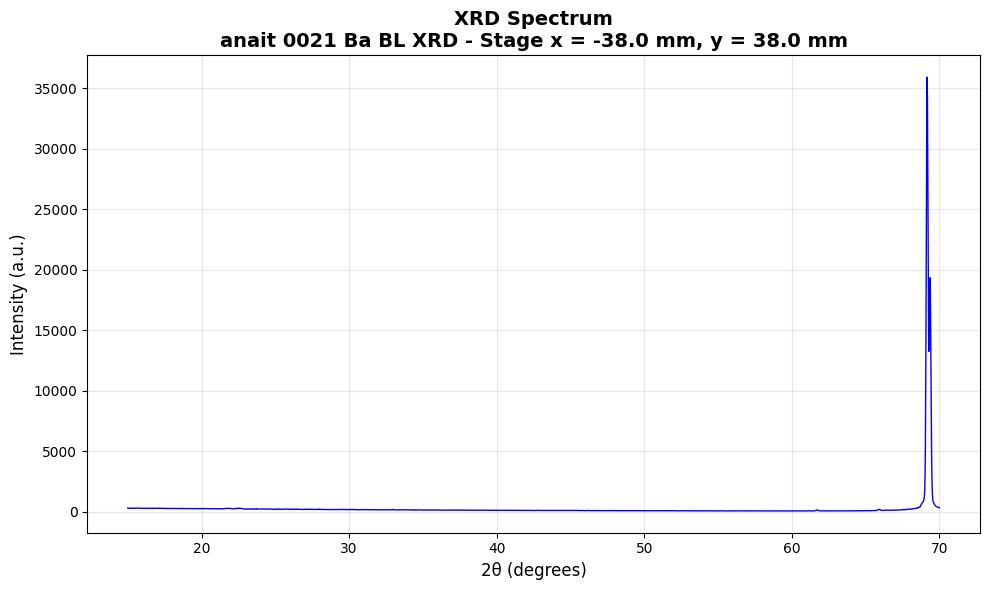

   💾 Saved: xrd_anait_0021_Ba_BL_XRD_Stage_x_=_-38.0_mm,_y_=_38.0_mm.csv
   💾 Saved: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png

[2/3] Processing: anait 0021 Ba BL XRD - Stage x = -29.0 mm, y = 38.0 mm
--------------------------------------------------------------------------------
   ✅ Data found: 5501 points
   📈 Plotting...


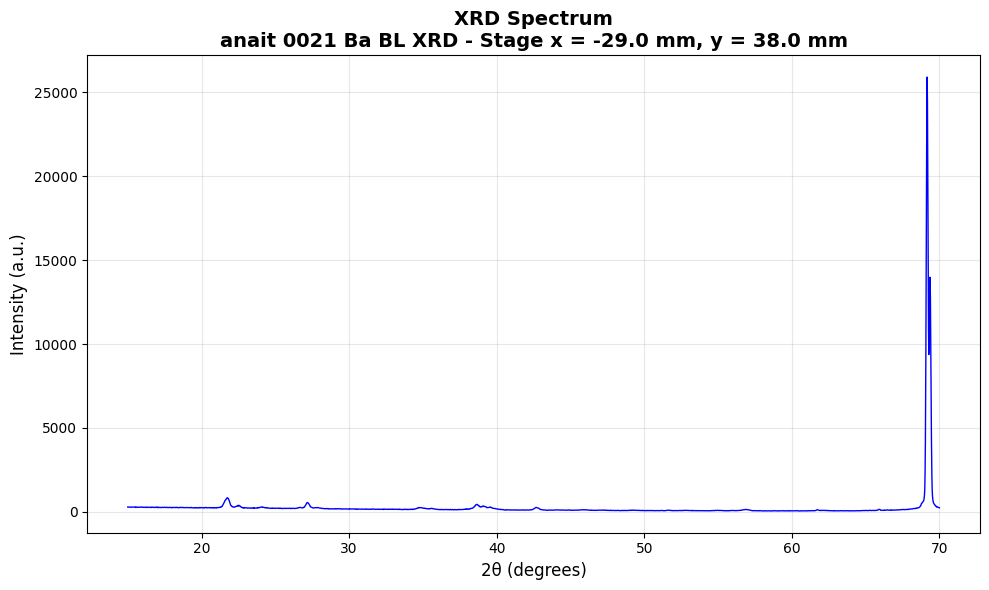

   💾 Saved: xrd_anait_0021_Ba_BL_XRD_Stage_x_=_-29.0_mm,_y_=_38.0_mm.csv
   💾 Saved: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png

[3/3] Processing: anait 0021 Ba BL XRD - Stage x = -20.0 mm, y = 38.0 mm
--------------------------------------------------------------------------------
   ✅ Data found: 5501 points
   📈 Plotting...


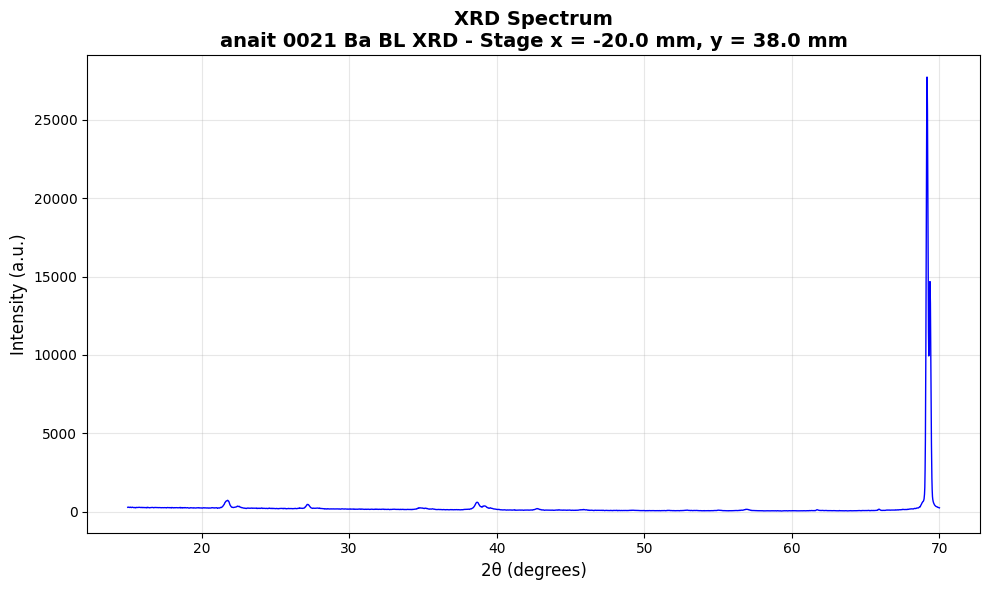

   💾 Saved: xrd_anait_0021_Ba_BL_XRD_Stage_x_=_-20.0_mm,_y_=_38.0_mm.csv
   💾 Saved: xrd_spectrum_1FWV7IADrj0BzjMtqrVjPkCmBLNb.png

✅ COMPLETED! Successfully plotted 3/3 point(s)

📁 Files saved in current directory:
   c:\Users\anait\OneDrive - Danmarks Tekniske Universitet\Documents\GitHub\codes-in-progress\Anat\API


In [ ]:
# ============================================================================
#  USER SELECTION - Choose which measurement point(s) to plot
# 📝  Select the measurement point(s) to plot:
SELECTED_POINTS = [1, 2, 3]  # Use the numbers from the list above
# ============================================================================

print("="*80)
print("📊 SELECTED XRD MEASUREMENT POINTS")
print("="*80)

if 'available_xrd_points' not in locals():
    print("❌ Error: Please run the previous cell first to search for XRD measurements")
else:
    selected_points = []
    
    for idx in SELECTED_POINTS:
        if idx in available_xrd_points:
            point_info = available_xrd_points[idx]
            selected_points.append(point_info)
            print(f"\n✅ [{idx}] {point_info['entry_name']} - {point_info['point_name']}")
        else:
            print(f"\n⚠️  [{idx}] Invalid selection (not in available list)")
    
    if selected_points:
        print(f"\n{'='*80}")
        print(f"📈 Ready to plot {len(selected_points)} XRD measurement point(s)")
        print(f"{'='*80}")
        print(f"\n💡 Run the next cell to fetch data and plot!")
    else:
        print(f"\n❌ No valid selections. Please check SELECTED_POINTS values.")


if 'selected_points' not in locals() or not selected_points:
    print("❌ Error: Please run the previous cells first and select measurement points")
else:
    print("="*80)
    print(f"📊 PROCESSING {len(selected_points)} XRD MEASUREMENT POINT(S)")
    print("="*80)
    
    successfully_plotted = 0
    
    for i, point_info in enumerate(selected_points, 1):
        entry_name = point_info['entry_name']
        point_name = point_info['point_name']
        result_data = point_info['result_data']
        
        print(f"\n[{i}/{len(selected_points)}] Processing: {entry_name} - {point_name}")
        print("-"*80)
        
        # Search for XRD pattern data in this result
        def find_xrd_data(obj, path=""):
            if isinstance(obj, dict):
                if 'two_theta' in obj and 'intensity' in obj:
                    return path, obj
                if 'angle' in obj and 'intensity' in obj:
                    return path, obj
                if 'x' in obj and 'y' in obj:
                    return path, obj
                for key, value in obj.items():
                    result = find_xrd_data(value, f"{path}.{key}" if path else key)
                    if result:
                        return result
            elif isinstance(obj, list):
                for idx, item in enumerate(obj):
                    result = find_xrd_data(item, f"{path}[{idx}]")
                    if result:
                        return result
            return None
        
        xrd_location = find_xrd_data(result_data)
        
        if xrd_location:
            path, xrd_dict = xrd_location
            
            # Extract data
            two_theta = xrd_dict.get('two_theta') or xrd_dict.get('angle') or xrd_dict.get('x')
            intensity = xrd_dict.get('intensity') or xrd_dict.get('y')
            
            if two_theta and intensity:
                print(f"   ✅ Data found: {len(two_theta)} points")
                
                # Create data dictionary
                xrd_data = {
                    'two_theta': two_theta,
                    'intensity': intensity,
                    'entry_name': f"{entry_name} - {point_name}",
                    'entry_id': point_info['entry_id']
                }
                
                # Plot
                print(f"   📈 Plotting...")
                plot_xrd_spectrum(xrd_data, point_info['entry_id'])
                
                # Save CSV with unique name
                df = pd.DataFrame({
                    '2theta': two_theta,
                    'intensity': intensity
                })
                safe_name = f"{entry_name}_{point_name}".replace(' ', '_').replace('/', '_')
                csv_filename = f"xrd_{safe_name}.csv"
                df.to_csv(csv_filename, index=False)
                
                print(f"   💾 Saved: {csv_filename}")
                print(f"   💾 Saved: xrd_spectrum_{point_info['entry_id']}.png")
                
                successfully_plotted += 1
            else:
                print(f"   ❌ Could not extract two_theta/intensity arrays")
        else:
            print(f"   ❌ No XRD pattern data found")
    
    print("\n" + "="*80)
    print(f"✅ COMPLETED! Successfully plotted {successfully_plotted}/{len(selected_points)} point(s)")
    print("="*80)
    
    if successfully_plotted > 0:
        print(f"\n📁 Files saved in current directory:")
        import os
        print(f"   {os.getcwd()}")